In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(512, 512)


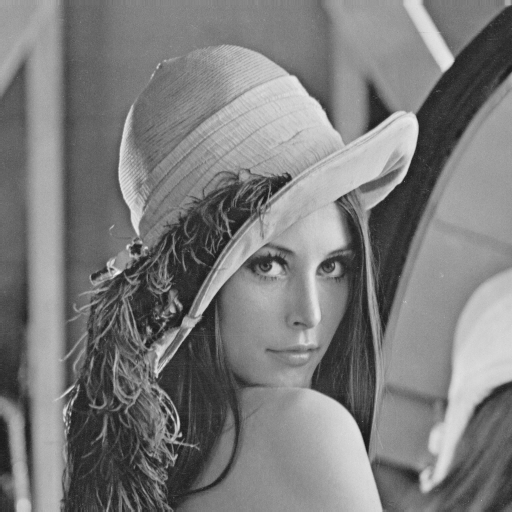

In [3]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena.jpg')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(gimg.shape)
cv2_imshow(gimg)

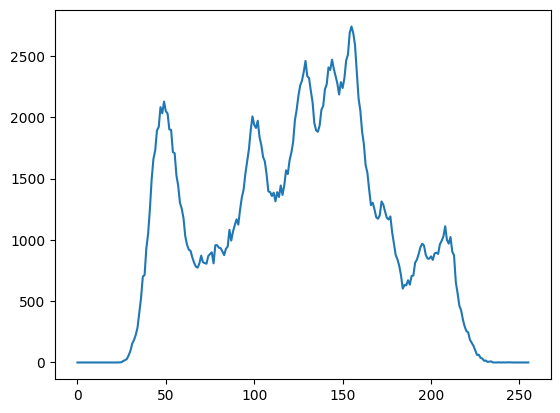

In [4]:
hist=cv2.calcHist([gimg],[0],None,[256],[0,256])
plt.plot(hist)
plt.show()

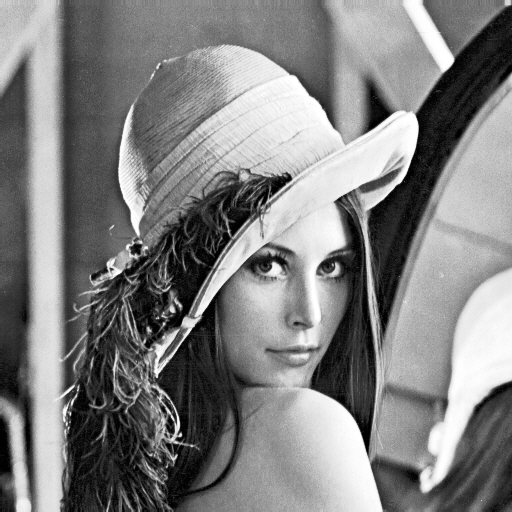

In [5]:
gOut=cv2.equalizeHist(gimg)
cv2_imshow(gOut)

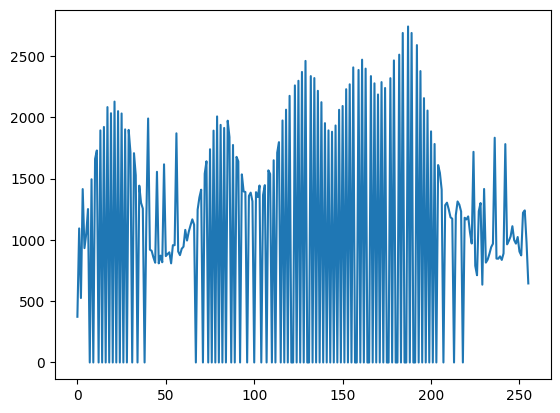

In [6]:
hist2 = cv2.calcHist([gOut], [0], None, [256], [0, 256])
plt.plot(hist2)
plt.show()


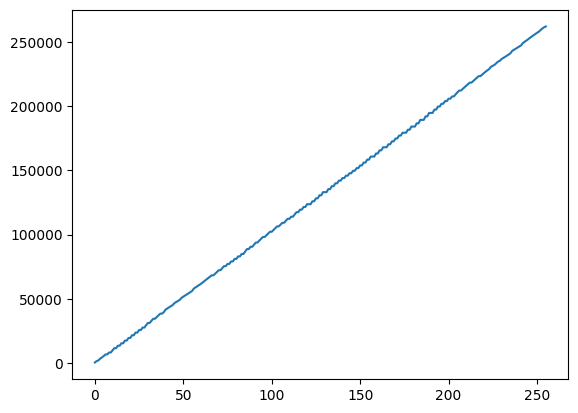

In [11]:
cumlHist = hist2.copy()
for i in range(1, len(cumlHist)):
    cumlHist[i] = cumlHist[i - 1] + hist2[i]

plt.plot(cumlHist)
plt.show()

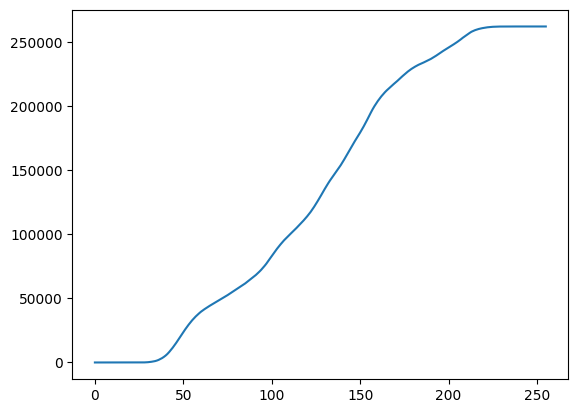

In [12]:
eqHist = hist.copy()

for i in range(len(eqHist)):
    eqHist[i] = eqHist[i-1] + hist[i]

plt.plot(eqHist)
plt.show()

262144


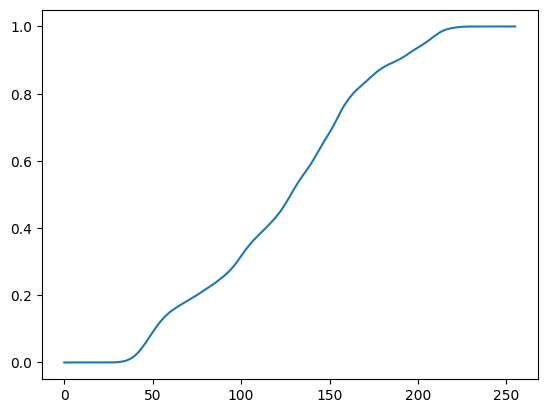

In [13]:
numOfPixels = np.int32(gimg.shape[0] * gimg.shape[1])
print(numOfPixels)
eqHist1 = eqHist/numOfPixels
plt.plot(eqHist1)
plt.show()

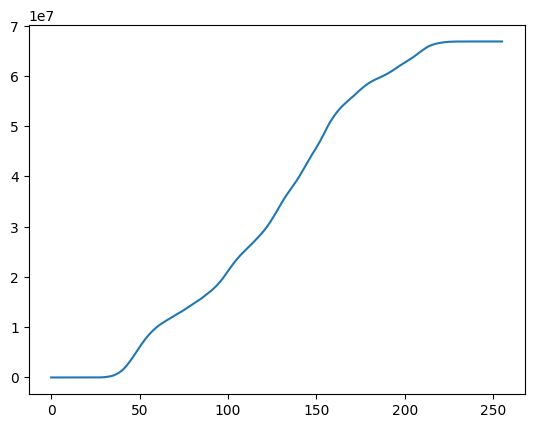

In [14]:
eqHist2 = eqHist * 255
plt.plot(eqHist2)
plt.show()

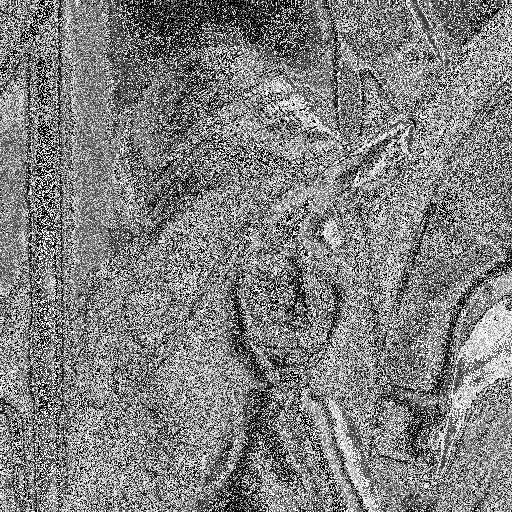

In [17]:
gOut1 = gimg.copy()
for i in range(gimg.shape[0]):
    for j in range(gimg.shape[1]):
        gOut1[i, j] = eqHist2[gimg[i, j]]

cv2_imshow(gOut1)
#what..?